In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter
from IPython.display import display

PROJECT_DIR = Path(r"C:\Users\Nam\Desktop\Palma")
RVFUNCS_DIR = PROJECT_DIR / "Spectral-toolkit-main"

# If your authoritative rvfuncs.py is directly in Palma, use:
# RVFUNCS_DIR = PROJECT_DIR

for directory in reversed([RVFUNCS_DIR, PROJECT_DIR]):
    location = str(directory)

    if location in sys.path:
        sys.path.remove(location)

    sys.path.insert(0, location)

import rvfuncs
import hd195592_common

from rvfuncs import (
    measure_epoch,
    plot_line_fit,
    gaussian_vel,
    fit_registration_profile,
    fit_trial_period,
    sinusoid,
)

from hd195592_common import (
    load_hermes,
    discover_spectra,
    write_csv,
    save_figure,
    velocity_to_wavelength,
)

plt.rcParams.update({"font.size": 14})

print("rvfuncs:", rvfuncs.__file__)
print("common:", hd195592_common.__file__)

rvfuncs: C:\Users\Nam\Desktop\Palma\Spectral-toolkit-main\rvfuncs.py
common: C:\Users\Nam\Desktop\Palma\hd195592_common.py


In [2]:
SPECTRA_DIR = PROJECT_DIR / "spectra"
OUTPUT_ROOT = PROJECT_DIR / "Output"

EXPECTED_RV = -27.0
MIN_LINES_FOR_MEAN = 3

SAVE_CSV = False
SAVE_FIGURES = False
SHOW_FIGURES = True

PRIMARY_RV_LINES = {
  #  "Si III 4553": (4552.62, 15.0),
   # "Si III 4568": (4567.84, 15.0),
    #"Si III 4575": (4574.76, 15.0),
    "Si IV 4089": (4088.86, 12.0),
    #"Si IV 4116": (4116.10, 12.0),
    #"He II 4200": (4199.83, 12.0),
    #"He II 4542": (4541.59, 7.0),
   # "He II 5412": (5411.52, 12.0),
    "Si III 4552": (4552.62, 15.0),
    "Si III 4567": (4567.84, 15.0),
   # "C III 4647": (4647.42, 15.0),
   # "C III 4650": (4650.25, 15.0),
}

SECONDARY_RV_LINES = {
    "He I 4026": (4026.19, 12.0),
    "He I 4388": (4387.93, 8.0),
    "He I 4471": (4471.48, 15.0),
    "He I 4713": (4713.14, 12.0),
    #"He I 4922": (4921.93, 15.0),
  #  "He I 5016": (5015.68, 15.0),
    #"He I 5876": (5875.62, 8.0),
 #   "He I 6678": (6678.15, 15.0),
   # "He I 7065": (7065.19, 10.0),
}


SINGLE_LINES = {
    **PRIMARY_RV_LINES,
    **SECONDARY_RV_LINES,
}

SPECIAL_PARAMS = {}

OUTPUT_DIR = (
    OUTPUT_ROOT
    / f"Selected_{len(SINGLE_LINES)}_Line_RV"
)

print(f"Selected RV lines: {len(SINGLE_LINES)}")
print("Output directory:", OUTPUT_DIR)
print("CSV writing:", SAVE_CSV)
print("Configured figure saving:", SAVE_FIGURES)

# Primary/secondary are legacy group labels,
# not identifications of separated stellar components.

Selected RV lines: 7
Output directory: C:\Users\Nam\Desktop\Palma\Output\Selected_7_Line_RV
CSV writing: False
Configured figure saving: False


In [4]:
spectrum_files = discover_spectra(SPECTRA_DIR)

if not spectrum_files:
    raise RuntimeError(
        f"No FITS spectra found in {SPECTRA_DIR}"
    )

epochs = []
load_failures = []

for index, path in enumerate(spectrum_files, start=1):
    print(
        f"\n[{index}/{len(spectrum_files)}] "
        f"{path.name}"
    )

    try:
        wave, flux, bjd = load_hermes(path)

        if not np.isfinite(bjd):
            raise ValueError("No valid BJD header.")

    except Exception as exc:
        load_failures.append({
            "file": str(path),
            "error": str(exc),
        })
        print("  Skipping spectrum:", exc)
        continue

    epoch = measure_epoch(
        wave,
        flux,
        path.name,
        bjd,
        primary_lines=PRIMARY_RV_LINES,
        secondary_lines=SECONDARY_RV_LINES,
        expected_rv=EXPECTED_RV,
        min_lines_for_mean=MIN_LINES_FOR_MEAN,
        special_params=SPECIAL_PARAMS,
    )

    epoch["path"] = path
    epochs.append(epoch)

if not epochs:
    raise RuntimeError("No usable epochs were found.")

from operator import itemgetter

epochs.sort(key=itemgetter("BJD"))


[1/17] 01186254_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  Si IV 4089    :    -9.31 km/s +/- 1.99
  Si III 4552   :    -8.63 km/s +/- 1.95
  Si III 4567   :   -14.71 km/s +/- 2.32
  He I 4026     :   -16.84 km/s +/- 1.42
  He I 4388     :   -13.02 km/s +/- 1.17
  He I 4471     :   -21.20 km/s +/- 1.06
  He I 4713     :    -8.84 km/s +/- 1.01

[2/17] 01186269_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  Si IV 4089    :    -8.86 km/s +/- 1.97
  Si III 4552   :    -8.13 km/s +/- 1.85
  Si III 4567   :   -10.98 km/s +/- 1.95
  He I 4026     :   -17.67 km/s +/- 1.10
  He I 4388     :   -12.02 km/s +/- 0.94
  He I 4471     :   -21.18 km/s +/- 1.02
  He I 4713     :    -7.90 km/s +/- 0.77

[3/17] 01186368_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  Si IV 4089    :   -22.00 km/s +/- 2.12
  Si III 4552   :   -35.15 km/s +/- 2.24
  Si III 4567   :   -35.51 km/s +/- 1.87
  He I 4026     :   -32.27 km/s +/- 0.95
  He I 4388     :   -27.65 km/s +/- 0.88
  He I 4471     :

In [5]:
# Assign exposure IDs once, before profile-registration fits.
for number, epoch in enumerate(epochs, start=1):
    epoch["epoch_number"] = number
    epoch["label"] = f"E{number:02d}"

epoch_table = pd.DataFrame([
    {
        "epoch": epoch["label"],
        "epoch_number": epoch["epoch_number"],
        "filename": epoch["filename"],
        "path": str(epoch["path"]),
        "BJD": epoch["BJD"],
    }
    for epoch in epochs
])

print(f"\nUsable epochs: {len(epochs)}")
display(epoch_table)

if load_failures:
    print("Excluded spectra:")
    display(pd.DataFrame(load_failures))


Usable epochs: 17


,epoch,epoch_number,filename,path,BJD
0,E01,1,20261005_01185398_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261005_01...,2.461319e+06
1,E02,2,20261005_01185403_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261005_01...,2.461319e+06
2,E03,3,20261006_01185510_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261006_01...,2.461320e+06
3,E04,4,20261006_01185516_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261006_01...,2.461320e+06
4,E05,5,20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261007_01...,2.461321e+06
5,E06,6,20261009_01185792_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261009_01...,2.461323e+06
6,E07,7,20261009_01185800_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261009_01...,2.461324e+06
7,E08,8,20261010_01185892_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261010_01...,2.461324e+06
8,E09,9,20261010_01185895_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261010_01...,2.461324e+06
9,E10,10,20261011_01186002_HRF_OBJ_ext_CosmicsRemoved_l...,C:\Users\Nam\Desktop\Palma\spectra\20261011_01...,2.461325e+06


In [6]:
line_rows = []
summary_rows = []

for epoch in epochs:
    for line_name, (rest, half_window) in SINGLE_LINES.items():
        line_rows.append({
            "filename": epoch["filename"],
            "BJD": epoch["BJD"],
            "line": line_name,
            "group": (
                "primary"
                if line_name in PRIMARY_RV_LINES
                else "secondary"
            ),
            "rest_wavelength_A": rest,
            "RV_kms": epoch["rvs"][line_name],
            "RV_error_kms": epoch["errors"][line_name],

            # Preserve the original CSV convention:
            # fit-result existence, not acceptance of the RV.
            "fit_success": (
                epoch["fits"][line_name] is not None
            ),
        })

    summary_rows.append({
        "filename": epoch["filename"],
        "BJD": epoch["BJD"],
        "combined_mean_RV_kms": epoch["mean_RV_kms"],
        "line_to_line_scatter_kms": (
            epoch["line_scatter_kms"]
        ),
        "N_combined_lines": epoch["N_mean_lines"],
        "primary_mean_RV_kms": (
            epoch["primary_mean_RV_kms"]
        ),
        "N_primary_lines": epoch["N_primary_lines"],
        "secondary_mean_RV_kms": (
            epoch["secondary_mean_RV_kms"]
        ),
        "N_secondary_lines": epoch["N_secondary_lines"],
    })

line_rows.sort(key=itemgetter("BJD", "line"))

line_rv_table = pd.DataFrame(line_rows)
mean_rv_table = pd.DataFrame(summary_rows)

display(mean_rv_table)

if SAVE_CSV or SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if SAVE_CSV:
    write_csv(
        OUTPUT_DIR / "individual_line_RVs_text.csv",
        line_rows,
    )
    write_csv(
        OUTPUT_DIR / "mean_RVs.csv",
        summary_rows,
    )

    print("CSV outputs written to:", OUTPUT_DIR)

,filename,BJD,combined_mean_RV_kms,line_to_line_scatter_kms,N_combined_lines,primary_mean_RV_kms,N_primary_lines,secondary_mean_RV_kms,N_secondary_lines
0,20261005_01185398_HRF_OBJ_ext_CosmicsRemoved_l...,2.461319e+06,-27.452219,4.016430,7,-25.536221,3,-28.889218,4
1,20261005_01185403_HRF_OBJ_ext_CosmicsRemoved_l...,2.461319e+06,-28.274649,4.281383,7,-27.051635,3,-29.191910,4
2,20261006_01185510_HRF_OBJ_ext_CosmicsRemoved_l...,2.461320e+06,-22.658339,4.084995,7,-21.438383,3,-23.573306,4
3,20261006_01185516_HRF_OBJ_ext_CosmicsRemoved_l...,2.461320e+06,-19.660987,3.970878,7,-18.741040,3,-20.350947,4
4,20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_l...,2.461321e+06,-3.337796,3.523962,7,-1.058751,3,-5.047079,4
5,20261009_01185792_HRF_OBJ_ext_CosmicsRemoved_l...,2.461323e+06,-29.758931,5.833008,7,-29.482351,3,-29.966365,4
6,20261009_01185800_HRF_OBJ_ext_CosmicsRemoved_l...,2.461324e+06,-28.039357,5.893718,7,-27.546469,3,-28.409024,4
7,20261010_01185892_HRF_OBJ_ext_CosmicsRemoved_l...,2.461324e+06,-17.388113,4.099493,7,-15.693163,3,-18.659326,4
8,20261010_01185895_HRF_OBJ_ext_CosmicsRemoved_l...,2.461324e+06,-16.760922,4.854211,7,-15.111680,3,-17.997854,4
9,20261011_01186002_HRF_OBJ_ext_CosmicsRemoved_l...,2.461325e+06,-36.977106,4.254036,7,-35.477565,3,-38.101762,4


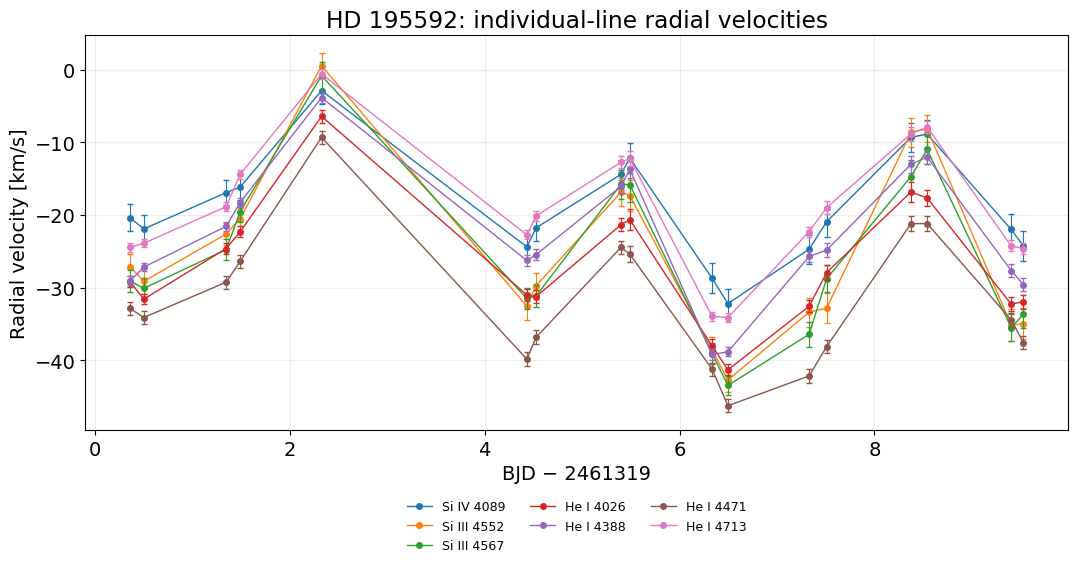

In [7]:
reference_bjd = int(
    np.floor(mean_rv_table["BJD"].min())
)

plot_time = (
    mean_rv_table["BJD"].to_numpy(float)
    - reference_bjd
)

fig_individual, ax = plt.subplots(figsize=(11, 6))

for line_name in SINGLE_LINES:
    values = np.array([
        epoch["rvs"][line_name]
        for epoch in epochs
    ])
    errors = np.array([
        epoch["errors"][line_name]
        for epoch in epochs
    ])

    valid = (
        np.isfinite(plot_time)
        & np.isfinite(values)
    )

    if not valid.any():
        continue

    line, = ax.plot(
        plot_time,
        np.where(valid, values, np.nan),
        "o-",
        markersize=4,
        linewidth=1.0,
        label=line_name,
    )

    good_errors = (
        valid
        & np.isfinite(errors)
        & (errors >= 0)
    )

    ax.errorbar(
        plot_time[good_errors],
        values[good_errors],
        yerr=errors[good_errors],
        fmt="none",
        color=line.get_color(),
        capsize=2.5,
        elinewidth=0.8,
    )

ax.set(
    xlabel=f"BJD − {reference_bjd}",
    ylabel="Radial velocity [km/s]",
    title="HD 195592: individual-line radial velocities",
)

ax.ticklabel_format(
    axis="x",
    style="plain",
    useOffset=False,
)
ax.grid(alpha=0.22)

if ax.get_legend_handles_labels()[0]:
    ax.legend(
        fontsize=9,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        frameon=False,
    )

fig_individual.tight_layout()

save_figure(
    fig_individual,
    OUTPUT_DIR,
    "02_individual_line_RVs_vs_BJD",
    save_figures=False,
    show_figures=SHOW_FIGURES,
)

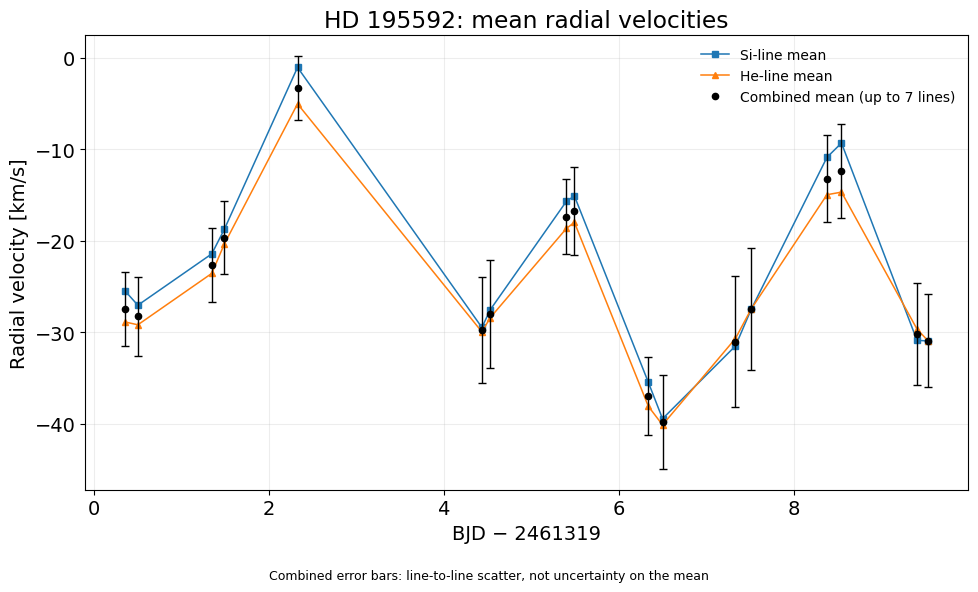

In [8]:
primary_label = (
    "Si-line mean"
    if PRIMARY_RV_LINES
    and all(
        name.strip().startswith("Si")
        for name in PRIMARY_RV_LINES
    )
    else "Group 1 mean"
)

secondary_label = (
    "He-line mean"
    if SECONDARY_RV_LINES
    and all(
        name.strip().startswith("He")
        for name in SECONDARY_RV_LINES
    )
    else "Group 2 mean"
)

combined_rv = mean_rv_table[
    "combined_mean_RV_kms"
].to_numpy(float)

combined_scatter = mean_rv_table[
    "line_to_line_scatter_kms"
].to_numpy(float)

fig_mean, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    plot_time,
    mean_rv_table["primary_mean_RV_kms"],
    "s-",
    color="tab:blue",
    markersize=5,
    linewidth=1.1,
    label=primary_label,
)

ax.plot(
    plot_time,
    mean_rv_table["secondary_mean_RV_kms"],
    "^-",
    color="tab:orange",
    markersize=5,
    linewidth=1.1,
    label=secondary_label,
)

ax.plot(
    plot_time,
    combined_rv,
    "ko",
    markersize=4.5,
    zorder=5,
    label=(
        f"Combined mean "
        f"(up to {len(SINGLE_LINES)} lines)"
    ),
)

good_errors = (
    np.isfinite(combined_rv)
    & np.isfinite(combined_scatter)
    & (combined_scatter >= 0)
)

ax.errorbar(
    plot_time[good_errors],
    combined_rv[good_errors],
    yerr=combined_scatter[good_errors],
    fmt="none",
    color="black",
    capsize=3,
    elinewidth=1.0,
    zorder=4,
)

ax.set(
    xlabel=f"BJD − {reference_bjd}",
    ylabel="Radial velocity [km/s]",
    title="HD 195592: mean radial velocities",
)
ax.ticklabel_format(
    axis="x",
    style="plain",
    useOffset=False,
)
ax.grid(alpha=0.22)
ax.legend(fontsize=10, frameon=False)

fig_mean.text(
    0.5,
    0.015,
    "Combined error bars: line-to-line scatter, "
    "not uncertainty on the mean",
    ha="center",
    fontsize=9,
)

fig_mean.tight_layout(rect=(0, 0.04, 1, 1))

save_figure(
    fig_mean,
    OUTPUT_DIR,
    "03_mean_RVs_vs_BJD",
    save_figures=SAVE_FIGURES,
    show_figures=SHOW_FIGURES,
)

In [9]:
RUN_FIT_GRID = False

if RUN_FIT_GRID:
    line_names = list(SINGLE_LINES)

    fig_grid, grid_axes = plt.subplots(
        len(line_names),
        len(epochs),
        figsize=(
            2.0 * len(epochs) + 0.8,
            1.35 * len(line_names) + 1.0,
        ),
        squeeze=False,
    )

    for col, epoch in enumerate(epochs):
        for row, line_name in enumerate(line_names):
            ax = grid_axes[row, col]
            rest, window = SINGLE_LINES[line_name]
            result = epoch["fits"][line_name]
            plotted = False

            if result is not None:
                try:
                    plot_line_fit(
                        epoch["wave"],
                        epoch["flux"],
                        rest,
                        result,
                        window=window,
                        title="",
                        ax=ax,
                    )
                    plotted = True

                except Exception as exc:
                    print(
                        "Fit plot failed:",
                        epoch["filename"],
                        line_name,
                        exc,
                    )
                    ax.clear()

            if not plotted:
                mask = (
                    np.abs(epoch["wave"] - rest)
                    <= window
                )
                ax.plot(
                    epoch["wave"][mask],
                    epoch["flux"][mask],
                    "k-",
                    linewidth=0.65,
                )
                ax.axvline(
                    rest,
                    color="0.5",
                    linestyle="--",
                    linewidth=0.6,
                )
                ax.text(
                    0.5,
                    0.65,
                    "FIT UNAVAILABLE",
                    transform=ax.transAxes,
                    ha="center",
                    fontsize=6,
                )

            ax.set(
                xlabel="",
                ylabel="",
                title="",
                xlim=(rest - window, rest + window),
            )

            legend = ax.get_legend()
            if legend is not None:
                legend.remove()

            ax.grid(color="0.9", linewidth=0.5)
            ax.tick_params(
                labelsize=6,
                labelbottom=(row == len(line_names) - 1),
                labelleft=(col == 0),
            )

            ax.xaxis.set_major_locator(
                MaxNLocator(nbins=4)
            )
            ax.yaxis.set_major_locator(
                MaxNLocator(nbins=4)
            )

            formatter = ScalarFormatter(useOffset=False)
            formatter.set_scientific(False)
            ax.xaxis.set_major_formatter(formatter)

            if col == 0:
                ax.set_ylabel(line_name, fontsize=9)

            if row == 0:
                ax.set_title(
                    f"{epoch['label']}\n"
                    f"BJD {epoch['BJD']:.4f}",
                    fontsize=8,
                )

            rv = epoch["rvs"][line_name]
            error = epoch["errors"][line_name]

            annotation = (
                f"{rv:.1f}"
                if np.isfinite(rv)
                else "RV unavailable"
            )

            if np.isfinite(rv) and np.isfinite(error):
                annotation += f" ± {error:.1f}"

            ax.text(
                0.04,
                0.96,
                annotation,
                transform=ax.transAxes,
                va="top",
                fontsize=6,
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.8,
                },
            )

    for axes_row in grid_axes:
        limits = [
            axis.get_ylim()
            for axis in axes_row
        ]
        lower = min(
            bounds[0] for bounds in limits
        )
        upper = max(
            bounds[1] for bounds in limits
        )

        for axis in axes_row:
            axis.set_ylim(lower, upper)

    fig_grid.suptitle(
        "HD 195592 — October 2026: "
        f"Gaussian fits to {len(line_names)} selected lines"
    )
    fig_grid.supxlabel("Wavelength [Å]")
    fig_grid.supylabel("Normalised flux")

    fig_grid.subplots_adjust(
        left=0.06,
        right=0.995,
        bottom=0.065,
        top=0.90,
        wspace=0.10,
        hspace=0.12,
    )

    save_figure(
        fig_grid,
        OUTPUT_DIR,
        "01_selected_line_fit_grid",
        save_figures=False,
        show_figures=SHOW_FIGURES,
    )

In [10]:
RUN_PHASE_FOLD = False

PHASE_PERIOD = 5.063
PHASE_T0 = None

if RUN_PHASE_FOLD:
    if (
        not np.isfinite(PHASE_PERIOD)
        or PHASE_PERIOD <= 0
    ):
        raise ValueError(
            "PHASE_PERIOD must be finite and positive."
        )

    bjds = mean_rv_table["BJD"].to_numpy(float)
    rvs = mean_rv_table[
        "combined_mean_RV_kms"
    ].to_numpy(float)
    scatter = mean_rv_table[
        "line_to_line_scatter_kms"
    ].to_numpy(float)

    valid = (
        np.isfinite(bjds)
        & np.isfinite(rvs)
    )

    if not valid.any():
        raise ValueError(
            "No valid BJD/RV measurements."
        )

    bjds = bjds[valid]
    rvs = rvs[valid]
    scatter = scatter[valid]

    phase_t0 = (
        float(bjds[np.argmax(rvs)])
        if PHASE_T0 is None
        else float(PHASE_T0)
    )

    if not np.isfinite(phase_t0):
        raise ValueError("PHASE_T0 must be finite.")

    phases = np.mod(
        (bjds - phase_t0) / PHASE_PERIOD,
        1.0,
    )

    fig_phase, ax = plt.subplots(figsize=(8, 4.8))

    ax.plot(
        phases,
        rvs,
        "o",
        color="steelblue",
        markersize=6,
        label="Combined retained-line mean",
    )

    good_errors = (
        np.isfinite(scatter)
        & (scatter >= 0)
    )

    ax.errorbar(
        phases[good_errors],
        rvs[good_errors],
        yerr=scatter[good_errors],
        fmt="none",
        color="steelblue",
        capsize=3,
    )

    ax.set(
        xlim=(-0.03, 1.03),
        xlabel=(
            "Phase "
            f"(adopted period = {PHASE_PERIOD:.3f} d)"
        ),
        ylabel="Radial velocity [km/s]",
        title="HD 195592: phase-folded combined RV",
    )
    ax.grid(alpha=0.22)
    ax.legend(frameon=False, fontsize=9)

    reference_label = (
        "observed RV maximum"
        if PHASE_T0 is None
        else "shared reference epoch"
    )

    fig_phase.text(
        0.5,
        0.045,
        f"Phase zero: BJD {phase_t0:.6f} "
        f"({reference_label})",
        ha="center",
        fontsize=9,
    )
    fig_phase.text(
        0.5,
        0.012,
        "Error bars: line-to-line scatter, "
        "not uncertainty on the mean",
        ha="center",
        fontsize=9,
    )

    fig_phase.tight_layout(rect=(0, 0.09, 1, 1))

    save_figure(
        fig_phase,
        OUTPUT_DIR,
        "04_phase_folded_RVs",
        save_figures=SAVE_FIGURES,
        show_figures=SHOW_FIGURES,
    )

    print(
        f"Adopted period: {PHASE_PERIOD:.6f} d; "
        f"plotting T0: {phase_t0:.6f} BJD"
    )

In [11]:
PROFILE_LINE_NAME = "He I 6678"
PROFILE_REST_A = 6678.149

PROFILE_VIEW_HALF = 300.0
PROFILE_FIT_HALF = 160.0
PROFILE_CONT_BOUNDS = (240.0, 340.0)

PROFILE_LOCAL_CONTINUUM = False
PROFILE_RESIDUAL_LIMIT = 0.04

PROFILE_EPOCH_SELECTION = "5,8,11,13"

PROFILE_INITIAL_RV_COLUMN = "combined_mean_RV_kms"

PROFILE_ADDITIONAL_SHIFT_KMS = 0.0
PROFILE_SHIFTS_BY_FILENAME = {}

print(
    "Profile initial-RV source:",
    PROFILE_INITIAL_RV_COLUMN,
)

Profile initial-RV source: combined_mean_RV_kms


In [12]:
if PROFILE_INITIAL_RV_COLUMN not in mean_rv_table:
    raise ValueError(
        "Unknown profile initial-RV column: "
        f"{PROFILE_INITIAL_RV_COLUMN}"
    )

summary_by_file = mean_rv_table.set_index("filename")

n_total_epochs = len(epochs)
profile_cmap = plt.get_cmap(
    "tab20" if n_total_epochs <= 20 else "turbo"
)

all_line_profiles = []
line_failures = []

for index, epoch in enumerate(epochs):
    try:
        initial = float(
            summary_by_file.loc[
                epoch["filename"],
                PROFILE_INITIAL_RV_COLUMN,
            ]
        )

        shift = float(
            PROFILE_SHIFTS_BY_FILENAME.get(
                epoch["filename"],
                PROFILE_ADDITIONAL_SHIFT_KMS,
            )
        )

        profile = fit_registration_profile(
            epoch["wave"],
            epoch["flux"],
            initial,
            rest_a=PROFILE_REST_A,
            shift_kms=shift,
            view_half=PROFILE_VIEW_HALF,
            fit_half=PROFILE_FIT_HALF,
            cont_bounds=PROFILE_CONT_BOUNDS,
            local_continuum=PROFILE_LOCAL_CONTINUUM,
        )

        colour = profile_cmap(
            index
            if n_total_epochs <= 20
            else index / max(n_total_epochs - 1, 1)
        )

        profile.update({
            "file": epoch["filename"],
            "BJD": epoch["BJD"],
            "epoch_number": epoch["epoch_number"],
            "label": epoch["label"],
            "colour": colour,
            "colour_hex": "#" + "".join(
                f"{int(round(255 * channel)):02x}"
                for channel in colour[:3]
            ),
        })

        all_line_profiles.append(profile)

    except (
        ValueError,
        RuntimeError,
        KeyError,
        OSError,
    ) as exc:
        line_failures.append({
            "epoch": epoch["label"],
            "file": epoch["filename"],
            "error": str(exc),
        })

if not all_line_profiles:
    raise RuntimeError(
        f"No usable profiles: {line_failures}"
    )

selection = (
    str(PROFILE_EPOCH_SELECTION)
    .strip()
    .lower()
)

if selection == "all":
    selected_numbers = [
        epoch["epoch_number"]
        for epoch in epochs
    ]
else:
    selected_numbers = [
        int(item.strip())
        for item in selection.split(",")
        if item.strip()
    ]

    if (
        not selected_numbers
        or len(selected_numbers)
        != len(set(selected_numbers))
    ):
        raise ValueError(
            "Empty selection or duplicate epoch numbers."
        )

    if any(
        number < 1 or number > n_total_epochs
        for number in selected_numbers
    ):
        raise ValueError(
            f"Available epochs: E01 to "
            f"E{n_total_epochs:02d}"
        )

selected_set = set(selected_numbers)

line_profiles = [
    profile
    for profile in all_line_profiles
    if profile["epoch_number"] in selected_set
]

if not line_profiles:
    raise RuntimeError(
        "No selected epochs have usable profiles."
    )

missing_selected = sorted(
    selected_set
    - {
        profile["epoch_number"]
        for profile in line_profiles
    }
)

if missing_selected:
    print(
        "Selected epochs unavailable after profile fitting:",
        missing_selected,
    )

line_mapping = pd.DataFrame([
    {
        "epoch": profile["label"],
        "BJD": profile["BJD"],
        "night": int(np.floor(profile["BJD"])),
        "file": profile["file"],
        "colour_hex": profile["colour_hex"],
        "Gaussian_RV_kms": profile["RV"],
        "fit_bound_hit": profile["bound_hit"],
    }
    for profile in line_profiles
])

display(line_mapping)

if line_failures:
    print("Excluded profiles:")
    display(pd.DataFrame(line_failures))

,epoch,BJD,night,file,colour_hex,Gaussian_RV_kms,fit_bound_hit
0,E05,2.461321e+06,2461321,20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_l...,#2ca02c,7.193252,False
1,E08,2.461324e+06,2461324,20261010_01185892_HRF_OBJ_ext_CosmicsRemoved_l...,#ff9896,-22.384773,False
2,E11,2.461325e+06,2461325,20261011_01186014_HRF_OBJ_ext_CosmicsRemoved_l...,#8c564b,-49.948989,False
3,E13,2.461327e+06,2461326,20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_l...,#e377c2,-53.538042,False


Median/residuals use selected epochs only; no extrapolation or depth scaling.
Gaussian registration RVs are diagnostics, not separated stellar velocities.


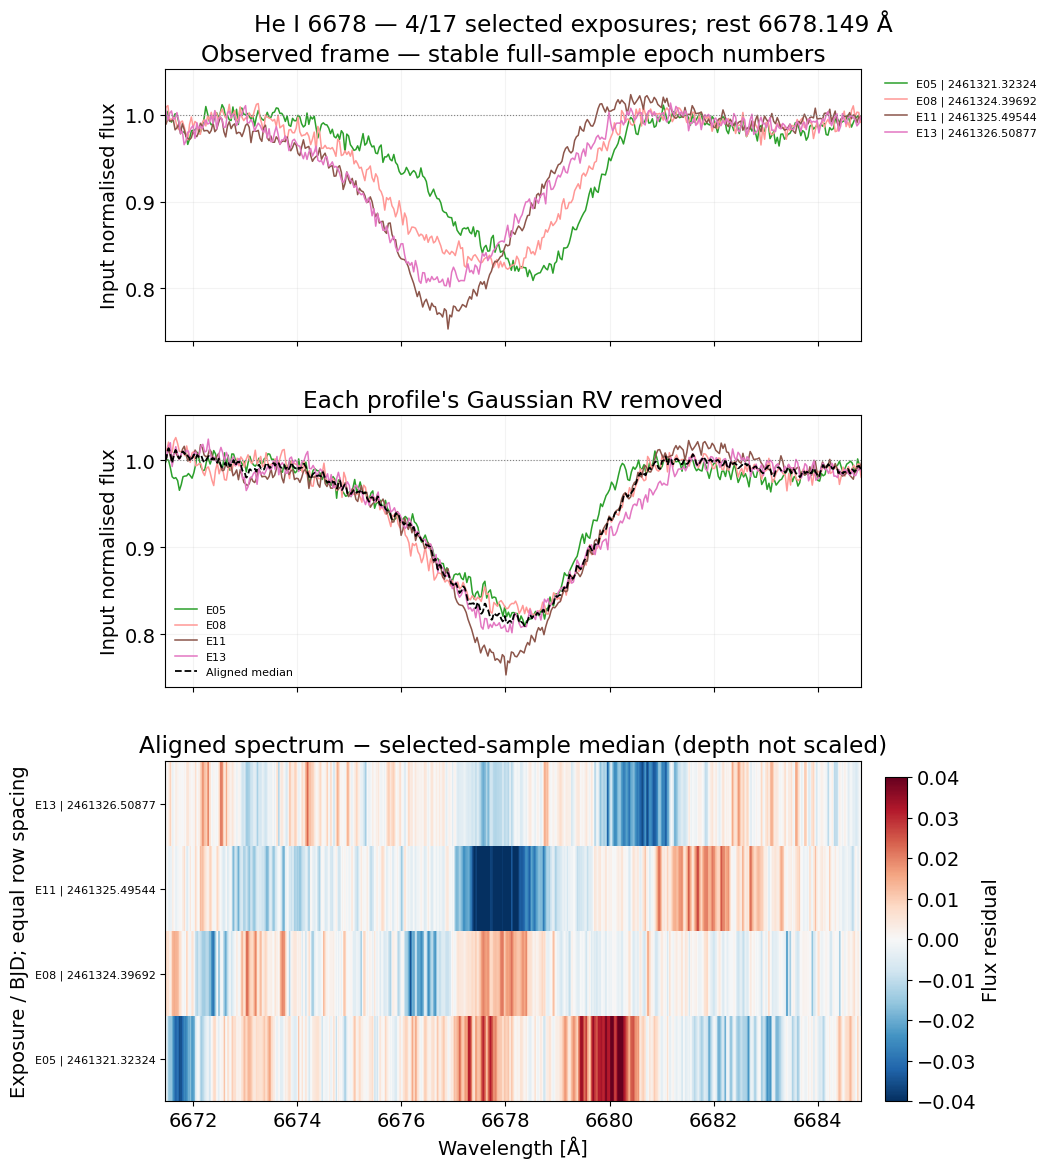

In [ ]:
profile_grid = np.linspace(
    -PROFILE_VIEW_HALF,
    PROFILE_VIEW_HALF,
    1001,
)

aligned_profiles = np.array([
    np.interp(
        profile_grid,
        profile["v"] - profile["RV"],
        profile["flux"],
        left=np.nan,
        right=np.nan,
    )
    for profile in line_profiles
])

valid_columns = np.any(
    np.isfinite(aligned_profiles),
    axis=0,
)

aligned_median = np.full(
    profile_grid.size,
    np.nan,
)

aligned_median[valid_columns] = np.nanmedian(
    aligned_profiles[:, valid_columns],
    axis=0,
)

line_residuals = (
    aligned_profiles
    - aligned_median[None, :]
)

fig_profiles, axes = plt.subplots(
    3,
    1,
    figsize=(12, 12),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2, 2, 2.5],
    },
)

for profile in line_profiles:
    observed_wave = velocity_to_wavelength(
        profile["v"],
        PROFILE_REST_A,
    )
    aligned_wave = velocity_to_wavelength(
        profile["v"] - profile["RV"],
        PROFILE_REST_A,
    )

    # This axis retains any explicit additive shift,
    # matching the earlier diagnostic convention.
    axes[0].plot(
        observed_wave,
        profile["flux"],
        color=profile["colour"],
        linewidth=1.1,
        label=(
            f"{profile['label']} | "
            f"{profile['BJD']:.5f}"
        ),
    )

    axes[1].plot(
        aligned_wave,
        profile["flux"],
        color=profile["colour"],
        linewidth=1.1,
        label=profile["label"],
    )

axes[0].set_title(
    "Observed frame — stable full-sample epoch numbers"
)
axes[1].set_title(
    "Each profile's Gaussian RV removed"
)

for ax in axes[:2]:
    ax.axhline(
        1.0,
        color="0.5",
        linestyle=":",
        linewidth=0.8,
    )
    ax.set_ylabel(
        "Locally normalised flux"
        if PROFILE_LOCAL_CONTINUUM
        else "Input normalised flux"
    )
    ax.grid(alpha=0.15)

axes[0].legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8,
    frameon=False,
)

profile_x = velocity_to_wavelength(
    profile_grid,
    PROFILE_REST_A,
)

axes[1].plot(
    profile_x,
    aligned_median,
    "k--",
    linewidth=1.3,
    label="Aligned median",
)
axes[1].legend(fontsize=8, frameon=False)

dx = profile_x[1] - profile_x[0]

x_edges = np.r_[
    profile_x[0] - dx / 2,
    (profile_x[:-1] + profile_x[1:]) / 2,
    profile_x[-1] + dx / 2,
]

image = axes[2].pcolormesh(
    x_edges,
    np.arange(len(line_profiles) + 1),
    np.ma.masked_invalid(line_residuals),
    cmap="RdBu_r",
    vmin=-PROFILE_RESIDUAL_LIMIT,
    vmax=PROFILE_RESIDUAL_LIMIT,
    shading="flat",
)

axes[2].set_yticks(
    np.arange(len(line_profiles)) + 0.5
)
axes[2].set_yticklabels([
    f"{profile['label']} | {profile['BJD']:.5f}"
    for profile in line_profiles
], fontsize=8)

axes[2].set(
    title=(
        "Aligned spectrum − selected-sample median "
        "(depth not scaled)"
    ),
    ylabel="Exposure / BJD; equal row spacing",
    xlabel="Wavelength [Å]",
)

profile_xlim = velocity_to_wavelength(
    [-PROFILE_VIEW_HALF, PROFILE_VIEW_HALF],
    PROFILE_REST_A,
)

for ax in axes:
    ax.set_xlim(*profile_xlim)
    ax.ticklabel_format(
        axis="x",
        style="plain",
        useOffset=False,
    )

fig_profiles.subplots_adjust(
    left=0.16,
    right=0.74,
    bottom=0.07,
    top=0.93,
    hspace=0.25,
)

colour_ax = fig_profiles.add_axes([
    0.76,
    0.07,
    0.018,
    0.27,
])

fig_profiles.colorbar(
    image,
    cax=colour_ax,
    label="Flux residual",
)

fig_profiles.suptitle(
    f"{PROFILE_LINE_NAME} — "
    f"{len(line_profiles)}/{n_total_epochs} "
    f"selected exposures; rest {PROFILE_REST_A:.3f} Å"
)

print(
    "Median/residuals use selected epochs only; "
    "no extrapolation or depth scaling."
)

save_figure(
    fig_profiles,
    OUTPUT_DIR,
    "profile_registration",
    save_figures=False,
    show_figures=SHOW_FIGURES,
)

In [14]:
PERIOD_RV_COLUMN = "secondary_mean_RV_kms"

PERIOD_CSV_PATH = None

P_MIN = 1.0
P_MAX = 20.0
N_TRIALS = 10000

LITERATURE_PERIOD = 5.063

In [ ]:
if not (0 < P_MIN < P_MAX) or N_TRIALS < 3:
    raise ValueError(
        "Require 0 < P_MIN < P_MAX "
        "and N_TRIALS >= 3."
    )

if (
    not np.isfinite(LITERATURE_PERIOD)
    or LITERATURE_PERIOD <= 0
):
    raise ValueError("LITERATURE_PERIOD must be finite and positive." )

period_table = ( mean_rv_table.copy() if PERIOD_CSV_PATH is None else pd.read_csv(Path(PERIOD_CSV_PATH)))

missing = [ column for column in ("BJD", PERIOD_RV_COLUMN) if column not in period_table ]

if missing:
    raise ValueError( f"Missing period-scan columns: {missing}")

period_time = pd.to_numeric(
    period_table["BJD"],
    errors="coerce",
).to_numpy(float)

period_rv = pd.to_numeric(
    period_table[PERIOD_RV_COLUMN],
    errors="coerce",
).to_numpy(float)

valid = (
    np.isfinite(period_time)
    & np.isfinite(period_rv)
)

period_time = period_time[valid]
period_rv = period_rv[valid]

order = np.argsort(period_time)
period_time = period_time[order]
period_rv = period_rv[order]

if len(period_rv) < 5 or np.ptp(period_time) == 0:
    raise ValueError( "Need at least five valid measurements " "and a nonzero time span."  )

period_reference = float(period_time[0])
period_t = period_time - period_reference
period_baseline = float(np.ptp(period_t))

frequencies = np.linspace(
    1 / P_MAX,
    1 / P_MIN,
    int(N_TRIALS),
)
trial_periods = 1 / frequencies

trial_rss = np.array([
    fit_trial_period(
        period_t,
        period_rv,
        period,
    )[0]
    for period in trial_periods
])

if not np.any(np.isfinite(trial_rss)):
    raise RuntimeError(
        "All trial-period designs are rank deficient."
    )

best_index = int(np.argmin(trial_rss))
best_period = float(trial_periods[best_index])

best_rss, best_coef, best_pred = fit_trial_period(
    period_t,
    period_rv,
    best_period,
)

lit_rss, lit_coef, lit_pred = fit_trial_period(
    period_t,
    period_rv,
    LITERATURE_PERIOD,
)

constant_rss = float(
    np.sum(
        (period_rv - np.mean(period_rv)) ** 2
    )
)

if constant_rss == 0:
    raise ValueError(
        "Constant RVs: period scan is uninformative."
    )

period_scan = {
    "time": period_time,
    "rv": period_rv,
    "reference": period_reference,
    "trial_periods": trial_periods,
    "rss": trial_rss,
    "best_period": best_period,
    "best_coefficients": best_coef,
    "adopted_coefficients": lit_coef,
}

print(
    "Period source:",
    "current in-memory mean_rv_table"
    if PERIOD_CSV_PATH is None
    else PERIOD_CSV_PATH,
)

print(
    f"Measurements: {len(period_rv)} | "
    f"Time span: {period_baseline:.3f} days"
)
print(
    f"Scan-best period: {best_period:.6f} days"
)
print(
    "Scan-best RMS: "
    f"{np.sqrt(best_rss / len(period_rv)):.3f} km/s"
)
print(
    "Adopted-period RMS: "
    f"{np.sqrt(lit_rss / len(period_rv)):.3f} km/s"
)
print(
    "Scan-best sinusoid semi-amplitude: "
    f"{np.hypot(best_coef[1], best_coef[2]):.3f} km/s"
)

if best_index in (0, len(trial_periods) - 1):
    print(
        "WARNING: Best period is at a scan boundary."
    )

if best_period > period_baseline:
    print(
        "WARNING: Best period exceeds the observing "
        "baseline and is poorly constrained."
    )

Period source: current in-memory mean_rv_table
Measurements: 17 | Time span: 9.173 days
Scan-best period: 3.051453 days
Scan-best RMS: 4.352 km/s
Adopted-period RMS: 8.113 km/s
Scan-best sinusoid semi-amplitude: 10.811 km/s
Unweighted descriptive fits: no period uncertainty or significance estimated.
Fitted offset is not necessarily the physical systemic velocity.
A scan-best period is a candidate timescale, not an established orbit.


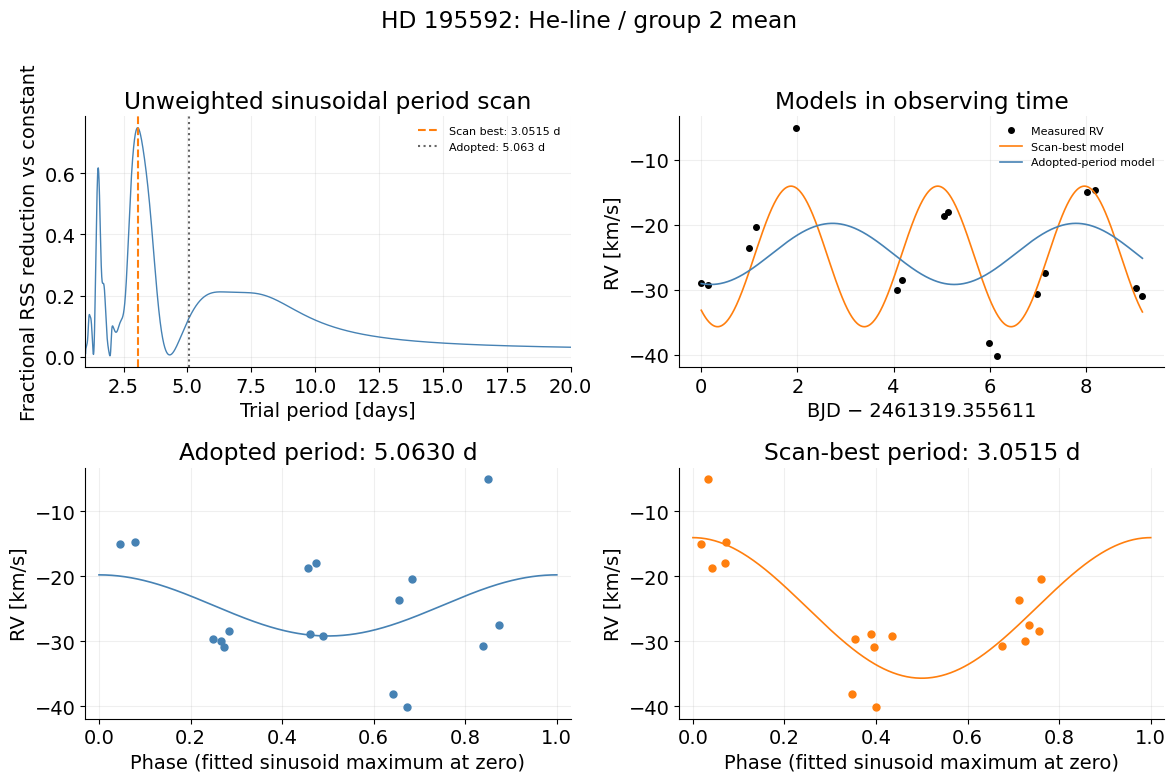

In [16]:
fig_period, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

scan_order = np.argsort(trial_periods)

ax = axes[0, 0]

ax.plot(
    trial_periods[scan_order],
    1 - trial_rss[scan_order] / constant_rss,
    color="steelblue",
    linewidth=1.0,
)

ax.axvline(
    best_period,
    color="tab:orange",
    linestyle="--",
    label=f"Scan best: {best_period:.4f} d",
)
ax.axvline(
    LITERATURE_PERIOD,
    color="0.4",
    linestyle=":",
    label=f"Adopted: {LITERATURE_PERIOD:g} d",
)

ax.set(
    xlim=(P_MIN, P_MAX),
    xlabel="Trial period [days]",
    ylabel="Fractional RSS reduction vs constant",
    title="Unweighted sinusoidal period scan",
)
ax.legend(fontsize=8, frameon=False)

ax = axes[0, 1]

ax.plot(
    period_t,
    period_rv,
    "ko",
    markersize=4,
    label="Measured RV",
)

dense_t = np.linspace(
    period_t.min(),
    period_t.max(),
    1500,
)

for period, coefficients, colour, label in [
    (
        best_period,
        best_coef,
        "tab:orange",
        "Scan-best model",
    ),
    (
        LITERATURE_PERIOD,
        lit_coef,
        "steelblue",
        "Adopted-period model",
    ),
]:
    # Linear cosine/sine coefficients -> existing sine-model API.
    amplitude = float(
        np.hypot(
            coefficients[1],
            coefficients[2],
        )
    )
    sine_phase = float(
        np.arctan2(
            coefficients[1],
            coefficients[2],
        )
    )

    curve = sinusoid(
        dense_t,
        coefficients[0],
        amplitude,
        sine_phase,
        period,
    )

    ax.plot(
        dense_t,
        curve,
        color=colour,
        linewidth=1.2,
        label=label,
    )

ax.set(
    xlabel=f"BJD − {period_reference:.6f}",
    ylabel="RV [km/s]",
    title="Models in observing time",
)
ax.legend(fontsize=8, frameon=False)

for ax, period, coefficients, colour, title in [
    (
        axes[1, 0],
        LITERATURE_PERIOD,
        lit_coef,
        "steelblue",
        "Adopted period",
    ),
    (
        axes[1, 1],
        best_period,
        best_coef,
        "tab:orange",
        "Scan-best period",
    ),
]:
    offset, cosine, sine = coefficients
    amplitude = float(np.hypot(cosine, sine))

    maximum_phase = (
        np.arctan2(sine, cosine)
        / (2 * np.pi)
    )

    phase = np.mod(
        period_t / period - maximum_phase,
        1.0,
    )
    phase_grid = np.linspace(0, 1, 500)

    ax.plot(
        phase,
        period_rv,
        "o",
        color=colour,
        markersize=5,
    )

    curve = sinusoid(
        phase_grid,
        offset,
        amplitude,
        np.pi / 2,
        1.0,
    )

    ax.plot(
        phase_grid,
        curve,
        color=colour,
        linewidth=1.2,
    )

    ax.set(
        xlim=(-0.03, 1.03),
        xlabel=(
            "Phase "
            "(fitted sinusoid maximum at zero)"
        ),
        ylabel="RV [km/s]",
        title=f"{title}: {period:.4f} d",
    )

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

series_labels = {
    "secondary_mean_RV_kms": (
        "He-line / group 2 mean"
    ),
    "primary_mean_RV_kms": (
        "Si-line / group 1 mean"
    ),
    "combined_mean_RV_kms": (
        "Combined retained-line mean"
    ),
}

fig_period.suptitle(
    "HD 195592: "
    + series_labels.get(
        PERIOD_RV_COLUMN,
        PERIOD_RV_COLUMN,
    )
)

fig_period.tight_layout(rect=(0, 0, 1, 0.96))

save_figure(
    fig_period,
    OUTPUT_DIR,
    "period_scan",
    save_figures=False,
    show_figures=SHOW_FIGURES,
)